[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/Ensemble_ICSPowerSystem_Vasan2025.ipynb)

# Quantum stacking ensemble (QSVC + QVC + QNN, Random-Forest meta-learner) for ICS power-system attacks: Vasan et al. 2025 step by step

**Paper.** Danish Vasan, Mohammad Shameem, Mohammad Hammoudeh, Mussadiq Abdul Rahim, Hamad Naeem and Adel F. Ahmed,
*Exploring Advanced Quantum Ensemble for Industrial Control Systems Security*, 33rd ACM International Conference on the
Foundations of Software Engineering (FSE Companion '25), Trondheim, 2025. DOI: [10.1145/3696630.3731620](https://doi.org/10.1145/3696630.3731620).

**What this notebook does.** It rebuilds the paper's experiment from scratch on the public Mississippi State University / Oak Ridge
National Laboratory *power-system attack* dataset (the paper's "real-time ICS power system dataset" with 78,377 rows and 129 columns):
a handful of rows is sampled, reduced with PCA to 2, 4 or 6 components (one component per qubit), and three quantum classifiers
(a quantum support-vector classifier, a variational quantum classifier and a quantum neural network) are trained and combined by a
*stacking* ensemble whose meta-learner is a classical Random Forest. Every number is compared with the paper's Table 1.
Because the paper's test sets contain only 39, 77 and 154 rows, we also repeat the experiment over several random seeds
and add classical baselines, so that you can judge how much of Table 1 is signal and how much is luck.

**How to run it.** Open it in Google Colab (CPU runtime is enough), choose *Runtime > Run all*. With `FAST_MODE = True` it finishes in about
10 minutes; `FAST_MODE = False` uses larger optimiser budgets, more seeds and all feature counts (runtime stated in the configuration cell).
Everything is simulated: no quantum hardware and no account are needed. The data (about 20 MB per archive) are downloaded by the notebook itself.

**What you get at the end.** Class distributions and 2-D scatter plots of the real measurements, the drawings of the circuits that are actually executed,
a results table (accuracy, precision, recall, F1) for each model, sample size and number of features, the confusion matrices, and a final cell that prints the
paper's numbers next to ours with one verdict per claim.

## The paper in one page

**Problem.** Industrial control systems (ICS) in the power grid are attacked by command injection, data injection and relay-setting changes.
A detector must separate *attack* traffic from *natural* disturbances (short circuits, line maintenance) and from no-event operation.
The authors ask whether combining several quantum classifiers helps when only very few qubits (2, 4 or 6) are available.

**Decision.** Binary classification: attack versus natural/no-event. The paper's text calls the *natural* instances the minority class (the dataset has
about 71 % attack rows) and its F1 score collapses to 0 when a model predicts only the majority (attack) class, which tells us the F1 score of Table 1 is
computed with **natural as the positive class**. This notebook therefore reports that orientation as the headline (so it is comparable with Table 1)
and also the attack-positive F1 that the rest of this repository uses.

**Method.**
1. Three base quantum classifiers: QSVC (quantum kernel + SVM, Eq. 2), QVC (variational circuit, Eq. 3: sign of an expectation value of Z) and QNN (layered circuit, Eq. 4).
2. A stacking ensemble (Eq. 5): a Random Forest receives the base models' posterior probabilities **and** the input features and gives the final label.

**Data.** "Real-time ICS power system dataset", 78,377 samples, 129 features (Section 4.1; the abstract says 78,345). It is the MSU/ORNL
power-system attack dataset (15 CSV files, 128 measurements + a marker). Preprocessing: normalisation, missing-value handling, PCA from 128 to 2 features
(Section 4.1; Table 1 uses 2, 4 and 6).

**Experiment.** Sample sizes 128, 256, 512; feature counts 2, 4, 6; test sizes 39, 77 and 154 (so a 70/30 split); metrics accuracy, precision, recall, F1 (Table 1, Fig. 5).

**Claims we can check.**
* C1: the ensemble beats every individual quantum classifier in every one of the 9 configurations (Section 5.4).
* C2: the individual classifiers have F1 = 0 at 512 samples (Sections 5.1-5.3) while the ensemble keeps a non-zero F1.
* C3: headline numbers, e.g. ensemble 128 samples / 6 features: accuracy 87.18 %, F1 89.80 %.
* C4: every other cell of Table 1 (36 rows).
* C5 (our addition, not in the paper): does the ensemble beat a plain Random Forest on the same inputs? That tells whether the quantum models contribute anything.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | "real-time ICS power system", 78,377 rows, 129 columns, ~71 % attack | MSU/ORNL power-system attack dataset, *binary* release (15 CSV files, 78,377 rows, 128 measurements + marker); downloaded from the maintainer's page, with the web.archive.org snapshot as fallback; SHA-256 checked. Not the authors' private copy, but the same public release |
| Positive class of P/R/F1 | not stated; implied *Natural* (minority) | Natural = positive for the headline (matches the paper's F1 = 0 collapse); attack-positive F1 also reported |
| How the n = 128 / 256 / 512 rows were drawn | not stated | CHOICE, two variants. `population`: uniform random sample without replacement from the de-duplicated pool (~29 % natural). `paper-implied`: natural share inferred from Table 1's recalls/accuracies (64 % at n=128, 27 % at n=256, 21 % at n=512), which a uniform random sample cannot produce at n=128 |
| Split | test sizes 39 / 77 / 154 | `train_test_split(test_size=0.3, stratify=y)` gives exactly 39 / 77 / 154 test rows |
| Preprocessing | normalisation, missing values, PCA to 2 / 4 / 6 | median imputation (inf -> NaN first) -> `StandardScaler` -> `PCA(k)` -> `MinMaxScaler((0, pi))`; test angles clipped to [0, pi]; **all fitted on the training rows only** |
| Encoding | angle encoding, Fig. 2 | one feature per qubit; `zz_feature_map` for QSVC and QVC, `z_feature_map` for QNN (CHOICE; the figures in the paper are images that cannot be recovered) |
| QSVC | quantum kernel + SVM | `zz_feature_map(k, reps=2, linear)`, exact fidelity kernel from statevectors, `SVC(kernel="precomputed", C=1)`; also a variant whose kernel bandwidth is tuned by cross-validation on the training rows |
| QVC | parameterised circuit, sign of `<Z>` (Eq. 3) | `zz_feature_map` + `real_amplitudes(k, reps=3)`, observable Z on all qubits (parity), `EstimatorQNN` + `NeuralNetworkClassifier`, squared loss, COBYLA |
| QNN | layers `U_l(theta_l)` (Eq. 4) | `z_feature_map(k, reps=2)` + `efficient_su2(k, reps=1)`, observable Z on qubit 0, same trainer, COBYLA |
| Optimiser, iterations, initial point, shots | not stated | COBYLA; `MAXITER` in the configuration cell; initial point uniform in [0, 2 pi); exact expectation values (no shot noise) |
| Meta-learner | Random Forest on posteriors + features (Eq. 5); how training posteriors were produced is not stated | RF with 200 trees. Two versions: **Ensemble (OOF)** trains the RF on out-of-fold posteriors (no leakage; the version we call "the ensemble") and **Ensemble (in-sample)** trains it on posteriors of base models evaluated on their own training rows (what a naive implementation does) |
| Repetitions | one run per cell | several seeds (configuration cell), mean and standard deviation |
| Classical baselines | none | `RandomForestClassifier` and `SVC(rbf)` on the same reduced inputs |

In [1]:
# Install (pinned to the versions tested for this notebook). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The guard avoids re-installing on a machine that already has the packages. A runtime restart may be needed after the install.
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("qiskit", "qiskit_aer", "qiskit_machine_learning", "py7zr", "requests"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "qiskit-aer==0.17.2",
                           "qiskit-ibm-runtime==0.50.0", "pylatexenc", "py7zr", "requests"])
    print("Installed. If Colab complains about numpy, use Runtime > Restart session and run again.")
else:
    print("All packages already available; skipping install.")

All packages already available; skipping install.


## 1. Configuration

Every tunable constant is here. `FAST_MODE = True` is the class-demo path (about 10 minutes on a CPU); `FAST_MODE = False` is the full path.

In [2]:
import os
from pathlib import Path

FAST_MODE = True            # True: class demo (~10 min).  False: full run (see the budgets below and the runtime note)
SEED = 42
DATA_DIR = Path(os.environ.get("QC161_DATA_DIR", "qc161_data"))   # downloaded archives are cached here
IBM_TOKEN = ""                  # unused: everything is simulated (real-hardware cells would run only if a token is set)

TEST_SIZE = 0.3                 # paper: test sets of 39 / 77 / 154 rows for n = 128 / 256 / 512 -> 30 %
N_LIST = [128, 256, 512]        # paper: sample sizes
K_LIST = [2, 6] if FAST_MODE else [2, 4, 6]      # paper: 2, 4, 6 features/qubits (FAST skips 4)
K_PM = [6] if FAST_MODE else [2, 4, 6]           # feature counts also run with the "paper-implied" class mix (see Section 3)
PAPER_MIX = {128: 0.64, 256: 0.27, 512: 0.21}    # share of natural (positive) rows implied by Table 1's recalls and accuracies
SEEDS = [42] if FAST_MODE else [42, 43, 44]      # sampling / split / initial-point seeds (paper: a single run)
MAXITER = 30 if FAST_MODE else 100               # COBYLA iterations for QVC and QNN (paper: not stated; COBYLA needs >= n_params + 2)
OOF_FOLDS = 2 if FAST_MODE else 3                # folds for the out-of-fold posteriors of the stacking ensemble
BW_GRID = [0.5, 1.0, 2.0]                        # kernel bandwidths tried by the tuned QSVC variant
N_PLOT = 6000                                    # real rows drawn in the exploration scatter plots
# Full run (FAST_MODE = False): 3 seeds, k = 2, 4, 6 for both class mixes, 100 COBYLA iterations, 3 OOF folds. About 5 hours on a 2-vCPU CPU
# (FAST_MODE = True took about 12 minutes on a busy 8-thread laptop). Lower SEEDS / MAXITER for something in between.
print(f"FAST_MODE={FAST_MODE}  K_LIST={K_LIST}  K_PM={K_PM}  SEEDS={SEEDS}  MAXITER={MAXITER}  OOF_FOLDS={OOF_FOLDS}")

FAST_MODE=True  K_LIST=[2, 6]  K_PM=[6]  SEEDS=[42]  MAXITER=30  OOF_FOLDS=2


In [3]:
import time, io, hashlib, warnings, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn, requests
from IPython.display import display

import qiskit, qiskit_aer, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, z_feature_map, real_amplitudes, efficient_su2
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED)
algorithm_globals.random_seed = SEED
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
T0 = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__,
      "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)

# Hugging Face token handling (required by the repository's rules). This dataset is NOT on Hugging Face and is not gated, so the token
# is never used here. If you point the download to a gated mirror, put your own token into Colab Secrets (Settings > Secrets > HF_TOKEN);
# never paste a token into the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1


## 2. Data: download, verify, clean

The dataset (Hink et al., MSU / Oak Ridge National Laboratory, "Power System Attack Datasets") is distributed as `.7z` archives of 15 CSV files.
The *binary* release has 78,377 rows and 129 columns (128 measurements from four phasor measurement units, control-panel and Snort log fields, plus a
`marker` column with the two labels *Natural* and *Attack*). We read the archive in memory (nothing is unpacked to disk), turn infinite values into missing
values (they are imputed later from the training rows only), and drop exact duplicate rows.

We also fetch the *multiclass* release of the same measurements. Its `marker` holds the scenario number (1 to 41); we use it **only to colour the exploration plots**
by scenario. The notebook checks that its measurements are identical to the binary release row by row and that each scenario falls entirely in one binary class.
The scenario numbers are not translated into attack names here (check the dataset documentation for that); we group them by numeric range only.

In [4]:
ARCHIVES = {
    "binary": dict(
        file="binaryAllNaturalPlusNormalVsAttacks.7z",
        sha256="b02c16bd74374d782298767708453570e4bc85e6a6e176c56a9c552358d472f8",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z",
              "http://web.archive.org/web/20240416093701id_/http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z"]),
    "multiclass": dict(
        file="multiclass.7z",
        sha256="ba27c1fa81c53fe2718734b9c6311a41b93cd73c86de0f86e59566a6d70e8555",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z",
              "http://web.archive.org/web/2024id_/http://www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z"]),
}

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def ensure_archive(key):
    spec = ARCHIVES[key]
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    dest = DATA_DIR / spec["file"]
    if dest.exists() and sha256_file(dest) == spec["sha256"]:
        return dest
    last = None
    for url in spec["urls"]:
        try:
            print("downloading", url)
            with requests.get(url, stream=True, timeout=180) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            if sha256_file(dest) == spec["sha256"]:
                return dest
            last = "SHA-256 mismatch"
        except Exception as e:
            last = repr(e)
    raise RuntimeError(f"could not obtain {spec['file']} with a matching SHA-256 ({last}). "
                       f"Download it manually and place it in {DATA_DIR.resolve()}.")

def read_archive(key):
    import py7zr
    arch = ensure_archive(key)
    import shutil
    tmp = DATA_DIR / f"_tmp_{key}"
    shutil.rmtree(tmp, ignore_errors=True); tmp.mkdir(parents=True)
    try:
        with py7zr.SevenZipFile(arch) as z:
            z.extractall(tmp)                 # unpacked only for the moment it takes to read the files into memory
        return {p.name: p.read_bytes() for p in sorted(tmp.rglob("*")) if p.is_file()}
    finally:
        shutil.rmtree(tmp, ignore_errors=True)    # keeps the disk free (the CSVs are ~80 MB)

def parse_arff(raw):
    lines = raw.decode("latin-1").splitlines()
    i = [k for k, l in enumerate(lines) if l.lower().startswith("@data")][0]
    names = [l.split()[1].strip("'") for l in lines[:i] if l.lower().startswith("@attribute")]
    return pd.read_csv(io.StringIO("\n".join(lines[i + 1:])), header=None, names=names)

# ---- binary release (the paper's task) ----
frames, fnames = [], []
for name, raw in read_archive("binary").items():
    d = pd.read_csv(io.BytesIO(raw)); d.columns = [c.strip() for c in d.columns]
    frames.append(d); fnames.append(name)
pooled = pd.concat(frames, ignore_index=True); del frames
FEAT = [c for c in pooled.columns if c != "marker"]
X_raw = pooled[FEAT].to_numpy(np.float64)
lab_raw = pooled["marker"].to_numpy()
raw_counts = pooled["marker"].value_counts().to_dict()
del pooled

# ---- multiclass release: scenario number per row, used only for colouring plots ----
SCEN = None
try:
    mframes = [parse_arff(raw) for raw in read_archive("multiclass").values()]
    m = pd.concat(mframes, ignore_index=True); del mframes
    assert list(m.columns) == FEAT + ["marker"], "column mismatch"
    assert np.allclose(m[FEAT].to_numpy(np.float64), X_raw, rtol=1e-5, atol=1e-6, equal_nan=True), "rows are not aligned"
    SCEN = m["marker"].astype(int).to_numpy(); del m
    ct = pd.crosstab(SCEN, lab_raw)
    assert (ct.gt(0).sum(axis=1) == 1).all(), "a scenario falls into both binary classes"
    print("multiclass release aligned with the binary release; scenarios:", len(ct), "| every scenario is purely Natural or purely Attack")
except Exception as e:
    print("multiclass release not used (plots will be coloured by the binary label only):", repr(e)[:200])

n_inf = int(np.isinf(X_raw).sum())
X_raw[np.isinf(X_raw)] = np.nan                  # infinite impedances -> NaN; imputed from the TRAIN rows later
y_nat = (lab_raw == "Natural").astype(np.int64)  # 1 = Natural (positive class of the paper's metrics), 0 = Attack
tmp = pd.DataFrame(X_raw); tmp["__y"] = y_nat
keep = (~tmp.duplicated()).to_numpy(); del tmp
X_all, y_all = X_raw[keep], y_nat[keep]
scen_all = SCEN[keep] if SCEN is not None else None
print(f"raw rows {len(X_raw):,} (paper: 78,377) | inf cells -> NaN: {n_inf:,} | after de-duplication {len(y_all):,} rows, {X_all.shape[1]} measurement columns")
print(f"Natural share: {y_all.mean():.3f}   Attack share: {1 - y_all.mean():.3f}   (paper: ~71 % attack)")

multiclass release aligned with the binary release; scenarios: 37 | every scenario is purely Natural or purely Attack


raw rows 78,377 (paper: 78,377) | inf cells -> NaN: 10,906 | after de-duplication 78,368 rows, 128 measurement columns
Natural share: 0.290   Attack share: 0.710   (paper: ~71 % attack)


## 3. Preprocessing: impute, standardise, PCA, angles

Exactly the paper's recipe (normalisation, missing values, PCA to *k* components) plus the angle scaling that the repository convention requires for angle encoding.
**Every transform is fitted on the training rows only**; test rows are clipped to the training range.

**Two ways of drawing the 128 / 256 / 512 rows.** The paper does not say how the rows were chosen, but Table 1 leaks the class mix of its test sets: the ensemble's recall of 0.84 / 0.88 / 0.92
at n = 128 corresponds to 25 positive test rows out of 39 (64 %), the recall 0.0952 = 2/21 at n = 256 to 21 of 77 (27 %), and the all-negative accuracy 0.792 at n = 512 to 32 positives of 154 (21 %).
A uniform random sample of this dataset has only about 29 % natural rows, so it cannot give 64 % at n = 128. We therefore run both:
* `population`: uniform random sample (about 29 % natural, the real class balance of the dataset);
* `paper-implied`: random sample with the natural share inferred from Table 1 (64 %, 27 %, 21 %), to test whether the paper's evaluation conditions rather than its models explain the numbers.
Which class is "positive" in the paper is itself an inference (see the summary at the top); the F1 collapse to 0 at n = 512 only makes sense if the positive class is the minority.

In [5]:
class Prep:
    # median-impute -> standardise -> PCA(k) -> MinMax to [0, pi]; all fitted on the TRAINING rows only
    def __init__(self, X_train, k, seed):
        self.imp = SimpleImputer(strategy="median").fit(X_train)
        self.sc = StandardScaler().fit(self.imp.transform(X_train))
        Zs = self.sc.transform(self.imp.transform(X_train))
        self.pca = PCA(n_components=k, random_state=seed).fit(Zs)
        self.mm = MinMaxScaler((0.0, np.pi)).fit(self.pca.transform(Zs))
    def pc(self, X):                                    # PCA coordinates
        return self.pca.transform(self.sc.transform(self.imp.transform(X)))
    def angles(self, X):                                # rotation angles in [0, pi]; test values outside the training range are clipped
        return np.clip(self.mm.transform(self.pc(X)), 0.0, np.pi)

def make_split(seed, n, k, mix="population"):
    # CHOICE: mix="population": n rows drawn uniformly at random (without replacement) from the de-duplicated pool (~29 % natural);
    #         mix="paper-implied": the same, but with the natural share that Table 1's recalls/accuracies imply (PAPER_MIX), see Section 3.
    # Then a stratified 70/30 split.
    rng = np.random.default_rng(seed)
    if mix == "population":
        idx = rng.choice(len(y_all), size=n, replace=False)
    else:
        n_nat = int(round(PAPER_MIX[n] * n))
        idx = np.concatenate([rng.choice(np.flatnonzero(y_all == 1), size=n_nat, replace=False),
                              rng.choice(np.flatnonzero(y_all == 0), size=n - n_nat, replace=False)])
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all[idx], random_state=seed)
    prep = Prep(X_all[tr], k, seed)
    return dict(tr=tr, te=te, prep=prep, Atr=prep.angles(X_all[tr]), Ate=prep.angles(X_all[te]), ytr=y_all[tr], yte=y_all[te])

sp = make_split(SEED, 512, max(K_LIST))
print("example split n=512, k=%d: train %d rows (%d natural), test %d rows (%d natural); test fraction %.3f"
      % (max(K_LIST), len(sp["tr"]), sp["ytr"].sum(), len(sp["te"]), sp["yte"].sum(), len(sp["te"]) / 512))
for n_ in N_LIST:
    s_ = make_split(SEED, n_, 2)
    print(f"  n={n_}: test rows {len(s_['te'])} (paper: {dict(zip([128,256,512],[39,77,154]))[n_]})")

example split n=512, k=6: train 358 rows (99 natural), test 154 rows (42 natural); test fraction 0.301
  n=128: test rows 39 (paper: 39)
  n=256: test rows 77 (paper: 77)
  n=512: test rows 154 (paper: 154)


## Dataset Exploration and Visualisation

Everything below uses the real measurements and their ground-truth labels, nothing is simulated or invented.
First the shapes, feature names and the original label values; then the real class distribution; then 2-D scatter plots in which every point is one real row,
coloured by its true label: first the raw PCA coordinates (PCA fitted on a training split), then the same coordinates scaled to [0, pi], which is what the quantum
circuits receive as rotation angles. The second row colours the same rows by **scenario number** from the multiclass release (when it could be loaded), so you can see
the finer structure behind the binary label.

X shape (rows, measurement columns): (78368, 128) | y shape: (78368,) | source files: 15
original `marker` labels (raw, before de-duplication): {'Attack': 55663, 'Natural': 22714}
after de-duplication: {'Natural': 22706, 'Attack': 55662}

128 feature names. First 12: ['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM3:V', 'R1-PA4:IH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PA6:IH', 'R1-PM6:I']
last 12: ['control_panel_log1', 'control_panel_log2', 'control_panel_log3', 'control_panel_log4', 'relay1_log', 'relay2_log', 'relay3_log', 'relay4_log', 'snort_log1', 'snort_log2', 'snort_log3', 'snort_log4']
feature groups (prefix -> number of columns): {'R1': 29, 'R2': 29, 'R3': 29, 'R4': 29, 'control_panel': 4, 'other': 4, 'snort': 4}


missing values after turning inf into NaN: 10874 cells in 6296 rows


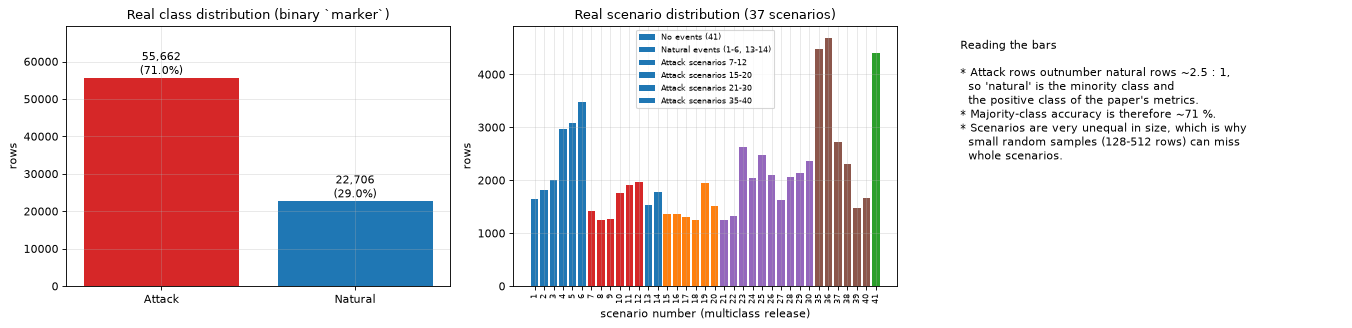

In [6]:
print("X shape (rows, measurement columns):", X_all.shape, "| y shape:", y_all.shape, "| source files:", len(fnames))
print("original `marker` labels (raw, before de-duplication):", raw_counts)
print("after de-duplication:", {"Natural": int(y_all.sum()), "Attack": int((1 - y_all).sum())})
print(f"\n{len(FEAT)} feature names. First 12:", FEAT[:12])
print("last 12:", FEAT[-12:])
grp = pd.Series(FEAT).str.extract(r"^(R\d+|control_panel|snort)", expand=False).fillna("other").value_counts()
print("feature groups (prefix -> number of columns):", grp.to_dict())
print("missing values after turning inf into NaN:", int(np.isnan(X_all).sum()), "cells in", int(np.isnan(X_all).any(axis=1).sum()), "rows")

GROUPS = [("No events (41)", [41], "tab:green"), ("Natural events (1-6, 13-14)", [1, 2, 3, 4, 5, 6, 13, 14], "tab:blue"),
          ("Attack scenarios 7-12", list(range(7, 13)), "tab:red"), ("Attack scenarios 15-20", list(range(15, 21)), "tab:orange"),
          ("Attack scenarios 21-30", list(range(21, 31)), "tab:purple"), ("Attack scenarios 35-40", list(range(35, 41)), "tab:brown")]

fig, ax = plt.subplots(1, 3 if scen_all is not None else 2, figsize=(17 if scen_all is not None else 11, 4.2))
cnt = [int((1 - y_all).sum()), int(y_all.sum())]
bars = ax[0].bar(["Attack", "Natural"], cnt, color=["tab:red", "tab:blue"])
for b_, c_ in zip(bars, cnt):
    ax[0].text(b_.get_x() + b_.get_width() / 2, c_, f"{c_:,}\n({c_ / sum(cnt):.1%})", ha="center", va="bottom")
ax[0].set_ylim(0, max(cnt) * 1.25); ax[0].set_ylabel("rows"); ax[0].set_title("Real class distribution (binary `marker`)")
if scen_all is not None:
    sv, sc_ = np.unique(scen_all, return_counts=True)
    col = {s: c for _, ids, c in GROUPS for s in ids}
    ax[1].bar([str(s) for s in sv], sc_, color=[col[s] for s in sv])
    ax[1].set_xlabel("scenario number (multiclass release)"); ax[1].set_ylabel("rows"); ax[1].tick_params(axis="x", labelsize=7, rotation=90)
    ax[1].set_title("Real scenario distribution (37 scenarios)")
    for name_, _, c_ in GROUPS:
        ax[1].bar([], [], color=c_, label=name_)
    ax[1].legend(fontsize=7)
ax[-1].axis("off")
ax[-1].text(0.0, 0.95, "Reading the bars\n\n* Attack rows outnumber natural rows ~2.5 : 1,\n  so 'natural' is the minority class and\n  the positive class of the paper's metrics.\n* Majority-class accuracy is therefore ~71 %.\n* Scenarios are very unequal in size, which is why\n  small random samples (128-512 rows) can miss\n  whole scenarios.", va="top", fontsize=10)
plt.tight_layout(); plt.show()

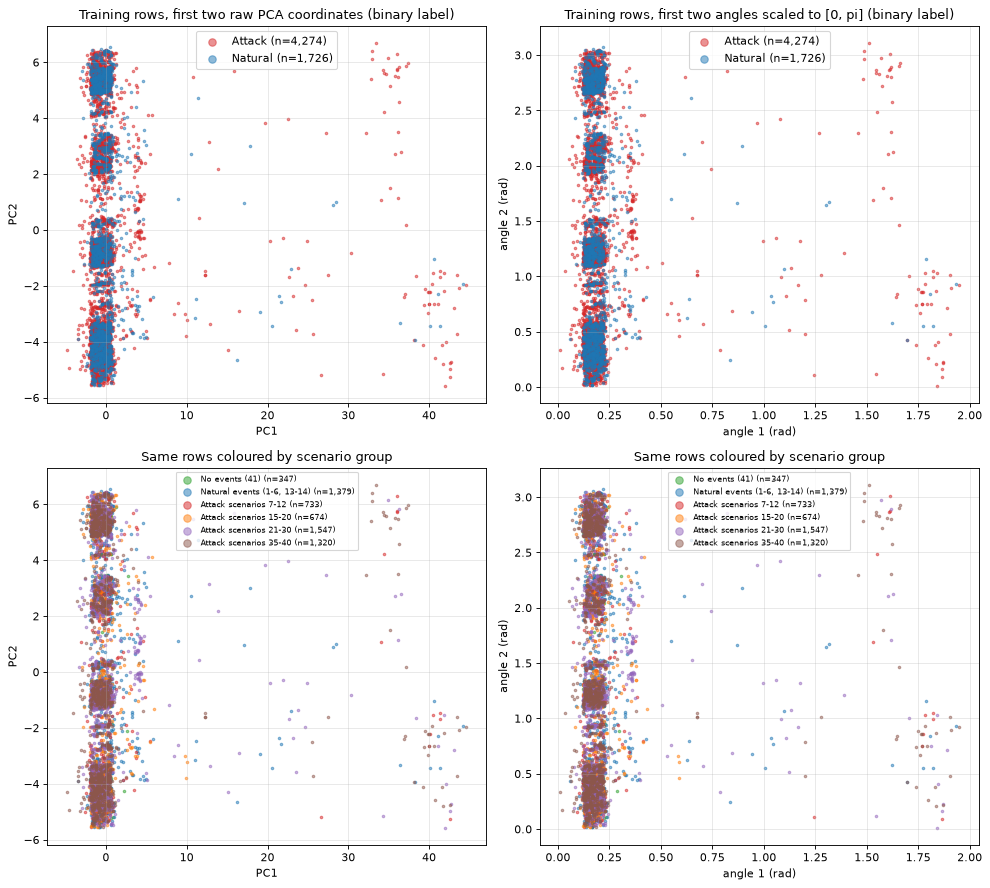

PCA-6 explained variance ratio: [0.145 0.117 0.088 0.07  0.06  0.045] | first two: 0.262 | total 0.526
Reading: natural and attack rows overlap strongly in the first two components, which is why the 2-qubit configurations of the paper are so hard.


In [7]:
# Scatter plots of REAL rows coloured by ground truth. PCA is fitted on the training split of a 70/30 stratified split of the full pool.
tr_all, te_all = train_test_split(np.arange(len(y_all)), test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
Pv = Prep(X_all[tr_all], 6, SEED)
sel = np.random.default_rng(SEED).choice(tr_all, size=min(N_PLOT, len(tr_all)), replace=False)
Zv = Pv.pc(X_all[sel]); Av = Pv.angles(X_all[sel]); yv = y_all[sel]
nrow = 2 if scen_all is not None else 1
fig, ax = plt.subplots(nrow, 2, figsize=(12.5, 5.6 * nrow), squeeze=False)
for j, (M, ttl, xl) in enumerate([(Zv, "raw PCA coordinates", "PC1"), (Av, "angles scaled to [0, pi]", "angle 1 (rad)")]):
    for lab, nm, c in [(0, "Attack", "tab:red"), (1, "Natural", "tab:blue")]:
        m_ = yv == lab
        ax[0, j].scatter(M[m_, 0], M[m_, 1], s=5, alpha=0.5, c=c, label=f"{nm} (n={m_.sum():,})")
    ax[0, j].set_title(f"Training rows, first two {ttl} (binary label)"); ax[0, j].set_xlabel(xl); ax[0, j].set_ylabel(xl.replace("1", "2")); ax[0, j].legend(markerscale=3)
    if scen_all is not None:
        sv_ = scen_all[sel]
        for name_, ids, c in GROUPS:
            m_ = np.isin(sv_, ids)
            ax[1, j].scatter(M[m_, 0], M[m_, 1], s=5, alpha=0.5, c=c, label=f"{name_} (n={m_.sum():,})")
        ax[1, j].set_title(f"Same rows coloured by scenario group"); ax[1, j].set_xlabel(xl); ax[1, j].set_ylabel(xl.replace("1", "2")); ax[1, j].legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()
ev = Pv.pca.explained_variance_ratio_
print("PCA-6 explained variance ratio:", np.round(ev, 3), "| first two:", round(float(ev[:2].sum()), 3), "| total", round(float(ev.sum()), 3))
print("Reading: natural and attack rows overlap strongly in the first two components, which is why the 2-qubit configurations of the paper are so hard.")

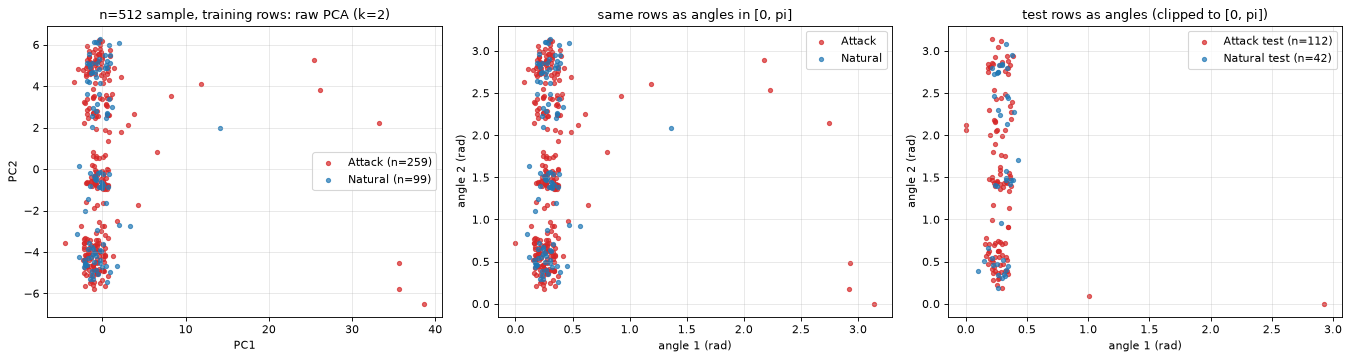

Each point is one real measurement row of the 358 training / 154 test rows of the n=512 sample; colours are the ground-truth labels.


In [8]:
# The same view for the rows an experiment actually sees: the 512-row sample (seed 42), its training part, PCA(2) and PCA(6) angles.
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
s2 = make_split(SEED, 512, 2)
for lab, nm, c in [(0, "Attack", "tab:red"), (1, "Natural", "tab:blue")]:
    m_ = s2["ytr"] == lab
    Z2 = s2["prep"].pc(X_all[s2["tr"]])
    ax[0].scatter(Z2[m_, 0], Z2[m_, 1], s=14, alpha=0.7, c=c, label=f"{nm} (n={m_.sum()})")
    ax[1].scatter(s2["Atr"][m_, 0], s2["Atr"][m_, 1], s=14, alpha=0.7, c=c, label=nm)
    mt = s2["yte"] == lab
    ax[2].scatter(s2["Ate"][mt, 0], s2["Ate"][mt, 1], s=14, alpha=0.7, c=c, label=f"{nm} test (n={mt.sum()})")
ax[0].set_title("n=512 sample, training rows: raw PCA (k=2)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend()
ax[1].set_title("same rows as angles in [0, pi]"); ax[1].set_xlabel("angle 1 (rad)"); ax[1].set_ylabel("angle 2 (rad)"); ax[1].legend()
ax[2].set_title("test rows as angles (clipped to [0, pi])"); ax[2].set_xlabel("angle 1 (rad)"); ax[2].set_ylabel("angle 2 (rad)"); ax[2].legend()
plt.tight_layout(); plt.show()
print("Each point is one real measurement row of the 358 training / 154 test rows of the n=512 sample; colours are the ground-truth labels.")

## Quantum Circuit Architecture

The paper shows its circuits only as pictures (Figs. 1 to 3) and gives no gate list, so the architectures below are our **assumptions**, marked `# CHOICE:`.
The drawings are of the circuit objects that the code later executes; the equivalence checks at the end of the section confirm that the simulators evaluate exactly these circuits.

* **QSVC**: angle encoding with a ZZ feature map (Hadamards, single-qubit phase rotations and `CX-P-CX` blocks between neighbouring qubits, repeated twice); the kernel is
  `K(a, b) = |<0|U(b)^dagger U(a)|0>|^2`, evaluated exactly from statevectors. There are no trainable circuit parameters (the SVM weights are classical).
* **QVC**: ZZ feature map followed by `RealAmplitudes` (RY rotations + CX ladder, 3 repetitions); output = expectation of `Z x ... x Z` (parity), label = its sign (Eq. 3).
* **QNN**: Z feature map (H + P, two repetitions) followed by `EfficientSU2` (RY, RZ + CX ladder, 1 repetition); output = expectation of Z on qubit 0 (Eq. 4).

=== QSVC (k=6): feature map U(x) ===


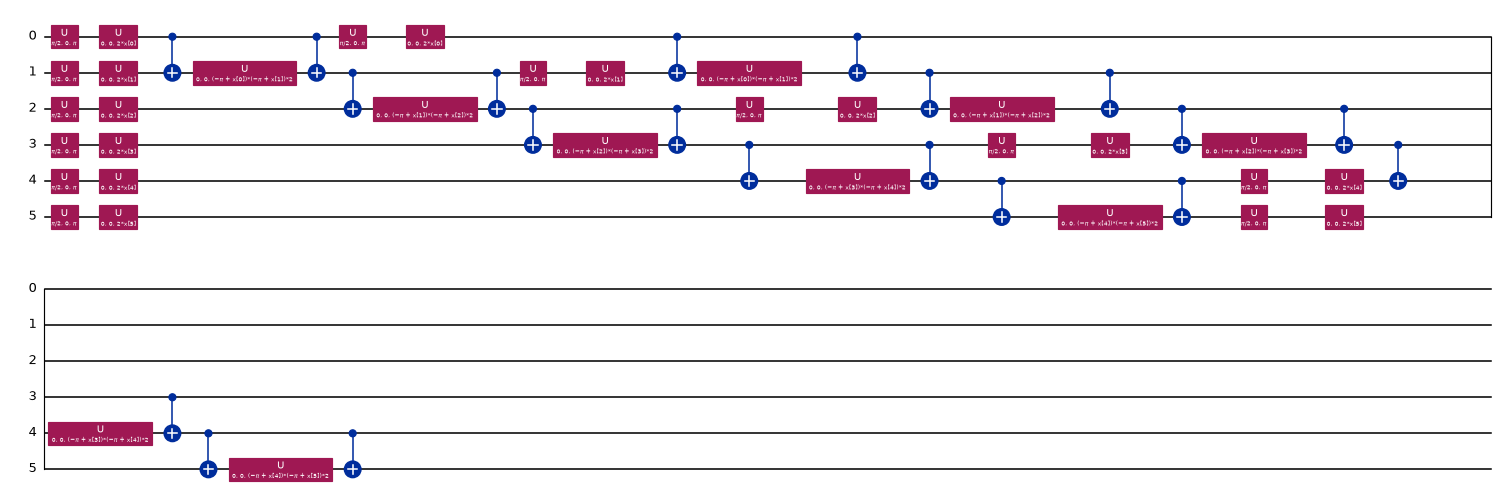

=== QSVC (k=6): fidelity-kernel circuit U(b)^dagger U(a) for one pair of rows (angles bound to example values) ===


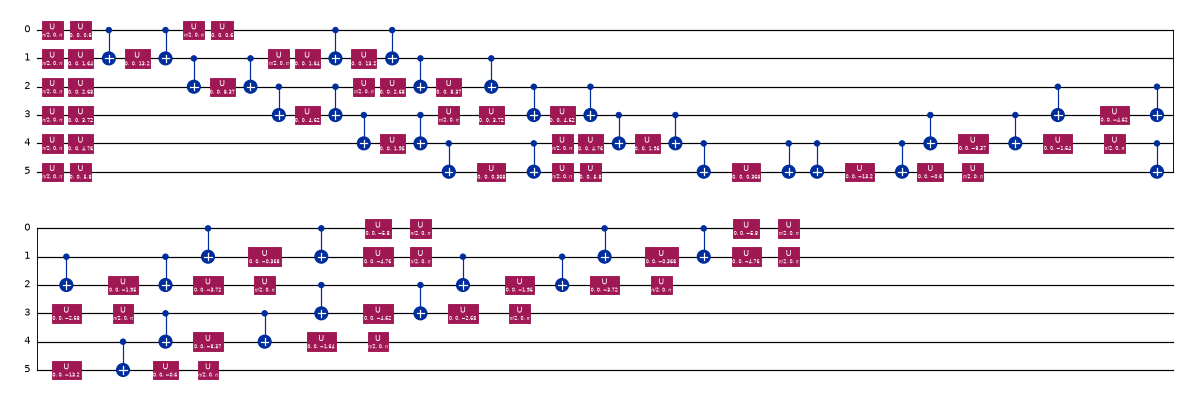

=== QVC (k=6): feature map + RealAmplitudes, measured observable Z^6 ===


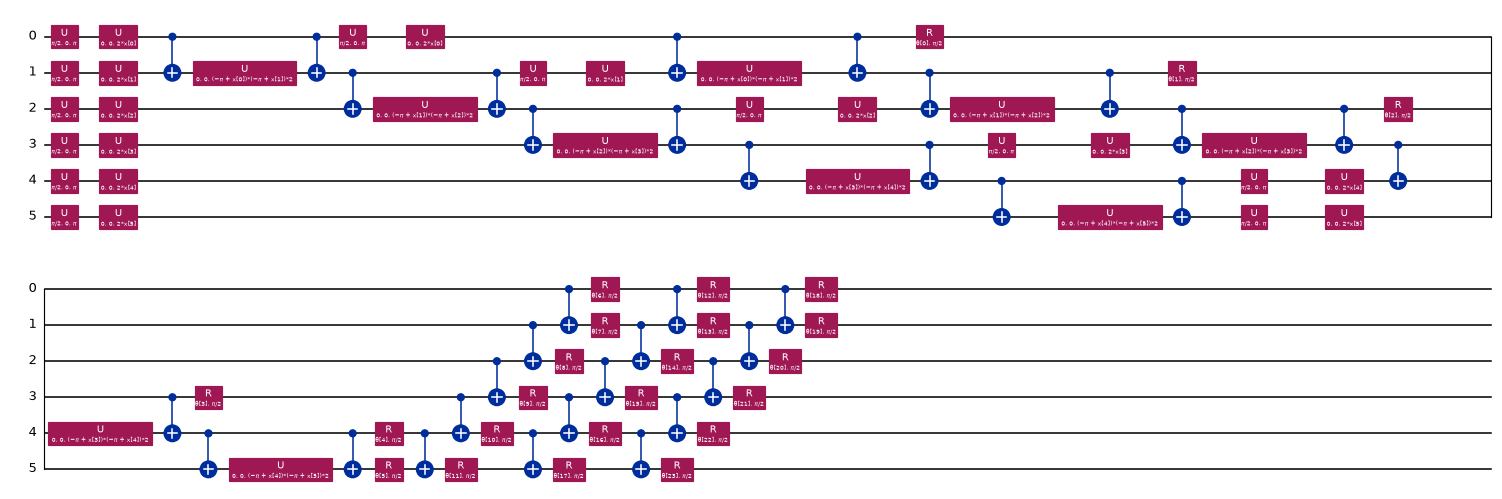

=== QNN (k=6): Z feature map + EfficientSU2, measured observable Z on qubit 0 ===


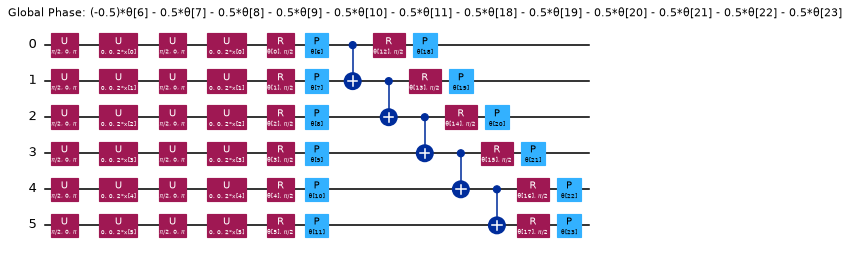

In [9]:
def qsvc_map(k):                       # CHOICE: ZZ feature map, 2 repetitions, linear entanglement
    return zz_feature_map(k, reps=2, entanglement="linear")

def build_qvc(k):                      # CHOICE: ZZ feature map + RealAmplitudes(reps=3), parity observable
    fm = zz_feature_map(k, reps=2, entanglement="linear"); an = real_amplitudes(k, reps=3)
    return fm, an, fm.compose(an), SparsePauliOp("Z" * k)

def build_qnn(k):                      # CHOICE: Z feature map + EfficientSU2(reps=1), Z on qubit 0
    fm = z_feature_map(k, reps=2); an = efficient_su2(k, reps=1, entanglement="linear")
    return fm, an, fm.compose(an), SparsePauliOp.from_sparse_list([("Z", [0], 1.0)], k)

K_DRAW = max(K_LIST)
fm_q = qsvc_map(K_DRAW)
vals = np.linspace(0.3, 2.9, K_DRAW)
kern_circ = fm_q.assign_parameters(vals).compose(fm_q.assign_parameters(vals[::-1]).inverse())   # U(a) followed by U(b)^dagger
print(f"=== QSVC (k={K_DRAW}): feature map U(x) ===")
display(fm_q.decompose().draw("mpl", fold=40, scale=0.7))
print(f"=== QSVC (k={K_DRAW}): fidelity-kernel circuit U(b)^dagger U(a) for one pair of rows (angles bound to example values) ===")
display(kern_circ.decompose().draw("mpl", fold=40, scale=0.55))
fm_v, an_v, qc_v, obs_v = build_qvc(K_DRAW)
print(f"=== QVC (k={K_DRAW}): feature map + RealAmplitudes, measured observable Z^{K_DRAW} ===")
display(qc_v.decompose().draw("mpl", fold=40, scale=0.7))
fm_n, an_n, qc_n, obs_n = build_qnn(K_DRAW)
print(f"=== QNN (k={K_DRAW}): Z feature map + EfficientSU2, measured observable Z on qubit 0 ===")
display(qc_n.decompose().draw("mpl", fold=40, scale=0.7))

In [10]:
rows = []
for k in sorted(set(K_LIST) | {2, 4, 6}):
    fm_k = qsvc_map(k); _, an1, qc1, _ = build_qvc(k); _, an2, qc2, _ = build_qnn(k)
    rows.append(dict(model="QSVC kernel (U(a), U(b)^+)", qubits=k, depth=2 * fm_k.decompose(reps=4).depth(), trainable_circuit_params=0, input_params=fm_k.num_parameters))
    rows.append(dict(model="QVC", qubits=k, depth=qc1.decompose(reps=4).depth(), trainable_circuit_params=an1.num_parameters, input_params=qc1.num_parameters - an1.num_parameters))
    rows.append(dict(model="QNN", qubits=k, depth=qc2.decompose(reps=4).depth(), trainable_circuit_params=an2.num_parameters, input_params=qc2.num_parameters - an2.num_parameters))
arch = pd.DataFrame(rows)
print("Executed circuits: qubits, depth (after full decomposition), trainable parameters, data-input parameters")
display(arch)

# ---- equivalence checks: the simulators evaluate exactly the drawn circuits ----
rng_c = np.random.default_rng(SEED)
def aer_est():
    return AerEstimator(options={"default_precision": 0.0, "backend_options": {"method": "statevector"}})
for name, (fm, an, qc, obs) in {"QVC": build_qvc(4), "QNN": build_qnn(4)}.items():
    qnn = EstimatorQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters, observables=obs, estimator=aer_est(), default_precision=0.0)
    Xc = rng_c.uniform(0, np.pi, (5, 4)); wc = rng_c.uniform(0, 2 * np.pi, an.num_parameters)
    got = qnn.forward(Xc, wc)[:, 0]
    ref = [Statevector(qc.assign_parameters(dict(zip(list(fm.parameters) + list(an.parameters), list(x) + list(wc))))).expectation_value(obs).real for x in Xc]
    assert np.allclose(got, ref, atol=1e-9), name
    print(f"{name}: Aer estimator output equals the exact statevector expectation of the drawn circuit (max |diff| = {np.max(np.abs(got - np.array(ref))):.1e})")
print("QSVC kernel: Qiskit's FidelityStatevectorKernel against our hand-computed statevector overlaps ->", end=" ")
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
fm4 = qsvc_map(4); Xa = rng_c.uniform(0, np.pi, (6, 4)); Xb_ = rng_c.uniform(0, np.pi, (5, 4))
Kq = FidelityStatevectorKernel(feature_map=fm4).evaluate(Xa, Xb_)
Sa = np.array([Statevector(fm4.assign_parameters(a)).data for a in Xa]); Sb = np.array([Statevector(fm4.assign_parameters(b)).data for b in Xb_])
Kh = np.abs(Sa.conj() @ Sb.T) ** 2
assert np.allclose(Kq, Kh, atol=1e-9); print("equal")

Executed circuits: qubits, depth (after full decomposition), trainable parameters, data-input parameters


,model,qubits,depth,trainable_circuit_params,input_params
0,"QSVC kernel (U(a), U(b)^+)",2,20,0,2
1,QVC,2,17,8,2
2,QNN,2,9,8,2
3,"QSVC kernel (U(a), U(b)^+)",4,38,0,4
4,QVC,4,30,16,4
5,QNN,4,11,16,4
6,"QSVC kernel (U(a), U(b)^+)",6,50,0,6
7,QVC,6,38,24,6
8,QNN,6,13,24,6


QVC: Aer estimator output equals the exact statevector expectation of the drawn circuit (max |diff| = 8.9e-16)
QNN: Aer estimator output equals the exact statevector expectation of the drawn circuit (max |diff| = 1.9e-15)
QSVC kernel: Qiskit's FidelityStatevectorKernel against our hand-computed statevector overlaps -> 

equal

## 4. Models: QSVC, QVC, QNN, the stacking ensemble and the classical baselines

Each model has `fit(angles, labels)`, `predict` and `proba` (posterior of the *Natural* class). The two circuit-based classifiers are trained with COBYLA on the squared loss
between the circuit output (in [-1, 1]) and the label (-1 = attack, +1 = natural); the posterior is `(output + 1) / 2`.

**Stacking.** The Random-Forest meta-learner receives `[p_QSVC, p_QVC, p_QNN, x]` (Eq. 5). To avoid feeding it posteriors the base models produced on their own training rows,
the *Ensemble (OOF)* trains the meta-learner on **out-of-fold** posteriors (the base models are re-trained `OOF_FOLDS` times on part of the training rows). The *Ensemble (in-sample)*
variant uses the posteriors of the final base models on the rows they were trained on, which is what a naive pipeline does and what the paper's text does not exclude.

In [11]:
SV_CACHE = {}
def states(fm, k, bw, A):
    out = []
    for a in A:
        key = (k, float(bw), a.tobytes())
        if key not in SV_CACHE:
            SV_CACHE[key] = Statevector(fm.assign_parameters(bw * a)).data
        out.append(SV_CACHE[key])
    return np.array(out)

class QSVCModel:
    # quantum-kernel SVM: exact fidelity kernel from statevectors + SVC(precomputed)
    def __init__(self, k, seed, bw=1.0, tune=False, C=1.0):
        self.k, self.seed, self.bw, self.tune, self.C = k, seed, bw, tune, C
        self.fm = qsvc_map(k)
    def K(self, A, B, bw):
        return np.abs(states(self.fm, self.k, bw, A).conj() @ states(self.fm, self.k, bw, B).T) ** 2
    def fit(self, A, y):
        if self.tune:   # bandwidth chosen by 3-fold CV on the TRAINING rows only
            best, best_s = self.bw, -1
            for bw in BW_GRID:
                Kt = self.K(A, A, bw); sc = []
                for a, b in StratifiedKFold(3, shuffle=True, random_state=self.seed).split(A, y):
                    s = SVC(kernel="precomputed", C=self.C).fit(Kt[np.ix_(a, a)], y[a])
                    sc.append(balanced_accuracy_score(y[b], s.predict(Kt[np.ix_(b, a)])))
                if np.mean(sc) > best_s: best, best_s = bw, float(np.mean(sc))
            self.bw = best
        self.A = A
        self.svc = SVC(kernel="precomputed", C=self.C, probability=True, random_state=self.seed).fit(self.K(A, A, self.bw), y)
        return self
    def predict(self, A):
        return self.svc.predict(self.K(A, self.A, self.bw))
    def proba(self, A):
        return self.svc.predict_proba(self.K(A, self.A, self.bw))[:, list(self.svc.classes_).index(1)]

class EstQNNModel:
    # circuit classifier: EstimatorQNN (exact expectation values on Aer) trained by NeuralNetworkClassifier + COBYLA
    def __init__(self, kind, k, seed, maxiter):
        self.kind, self.k, self.seed = kind, k, seed
        self.fm, self.an, self.qc, self.obs = (build_qvc if kind == "QVC" else build_qnn)(k)
        self.maxiter = max(maxiter, self.an.num_parameters + 2)       # COBYLA needs at least n_params + 2 evaluations
        self.qnn = EstimatorQNN(circuit=self.qc, input_params=self.fm.parameters, weight_params=self.an.parameters,
                                observables=self.obs, estimator=aer_est(), default_precision=0.0)
        self.hist = []
    def fit(self, A, y):
        init = np.random.default_rng(self.seed).uniform(0, 2 * np.pi, self.an.num_parameters)   # CHOICE: random initial point
        clf = NeuralNetworkClassifier(self.qnn, optimizer=COBYLA(maxiter=self.maxiter), initial_point=init,
                                      callback=lambda w, obj: self.hist.append(float(obj)))
        clf.fit(A, 2 * y - 1)
        self.w = np.asarray(clf.weights)
        return self
    def out(self, A):
        return self.qnn.forward(A, self.w)[:, 0]
    def predict(self, A):
        return (self.out(A) > 0).astype(int)
    def proba(self, A):
        return (self.out(A) + 1) / 2

class SVCbase:
    def __init__(self, seed): self.m = SVC(kernel="rbf", C=1.0, probability=True, random_state=seed)
    def fit(self, A, y): self.m.fit(A, y); return self
    def predict(self, A): return self.m.predict(A)
    def proba(self, A): return self.m.predict_proba(A)[:, list(self.m.classes_).index(1)]

class RFbase:
    def __init__(self, seed): self.m = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)
    def fit(self, A, y): self.m.fit(A, y); return self
    def predict(self, A): return self.m.predict(A)
    def proba(self, A): return self.m.predict_proba(A)[:, list(self.m.classes_).index(1)]

def make_base(name, k, seed):
    if name == "QSVC": return QSVCModel(k, seed)
    if name in ("QVC", "QNN"): return EstQNNModel(name, k, seed, MAXITER)
    raise ValueError(name)

def metrics(y, p):
    # positive class = Natural (paper orientation); attack-positive F1 is added for the repository convention
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), f1_attack=f1_score(1 - y, 1 - p, zero_division=0), tn=tn, fp=fp, fn=fn, tp=tp)

## 5. Running the experiment: sample sizes x feature counts x class mixes x seeds

For every (seed, class mix, n, k) the notebook trains QSVC, the tuned-bandwidth QSVC variant, QVC and QNN on the training rows, builds both ensembles, trains the two classical baselines on the same angles, and
scores everything on the held-out test rows. Progress and timings are printed. The COBYLA objective histories of the final base models are kept for a loss plot.

In [12]:
RECORDS, HISTS, CONF = [], {}, {}
T_RUN = time.time()
MIXES = (("population", K_LIST), ("paper-implied", K_PM))
for seed in SEEDS:
    for mix, ks in MIXES:
        for k in ks:
            for n in N_LIST:
                t_cfg = time.time()
                S = make_split(seed, n, k, mix)
                Atr, Ate, ytr, yte = S["Atr"], S["Ate"], S["ytr"], S["yte"]
                rec = lambda model, pred, t: RECORDS.append(dict(seed=seed, mix=mix, n=n, k=k, model=model, train_s=t, **metrics(yte, pred)))
                # ---- classical baselines on identical inputs ----
                for nm, cls in (("RF (classical)", RFbase), ("SVC-rbf (classical)", SVCbase)):
                    t0 = time.time(); m_ = cls(seed).fit(Atr, ytr); rec(nm, m_.predict(Ate), time.time() - t0)
                # ---- QSVC variants ----
                t0 = time.time(); q = make_base("QSVC", k, seed).fit(Atr, ytr); P_te = {"QSVC": q.proba(Ate)}; P_in = {"QSVC": q.proba(Atr)}
                rec("QSVC", q.predict(Ate), time.time() - t0)
                t0 = time.time(); qt = QSVCModel(k, seed, tune=True).fit(Atr, ytr); rec("QSVC (tuned bandwidth)", qt.predict(Ate), time.time() - t0)
                # ---- circuit classifiers: final fit on all training rows ----
                for nm in ("QVC", "QNN"):
                    t0 = time.time(); m_ = make_base(nm, k, seed).fit(Atr, ytr)
                    P_te[nm] = m_.proba(Ate); P_in[nm] = m_.proba(Atr)
                    rec(nm, m_.predict(Ate), time.time() - t0); HISTS[(seed, mix, n, k, nm)] = m_.hist
                # ---- out-of-fold posteriors for the meta-learner ----
                t0 = time.time()
                P_oof = {nm: np.zeros(len(ytr)) for nm in ("QSVC", "QVC", "QNN")}
                for a, b in StratifiedKFold(OOF_FOLDS, shuffle=True, random_state=seed).split(Atr, ytr):
                    for nm in P_oof:
                        P_oof[nm][b] = make_base(nm, k, seed).fit(Atr[a], ytr[a]).proba(Atr[b])
                t_oof = time.time() - t0
                order = ("QSVC", "QVC", "QNN")
                Z_te = np.column_stack([P_te[m] for m in order] + [Ate])
                for nm, Z_tr in (("Ensemble (OOF)", np.column_stack([P_oof[m] for m in order] + [Atr])),
                                 ("Ensemble (in-sample)", np.column_stack([P_in[m] for m in order] + [Atr]))):
                    meta = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1).fit(Z_tr, ytr)
                    rec(nm, meta.predict(Z_te), t_oof if "OOF" in nm else 0.0)
                for r_ in RECORDS[-8:]:
                    CONF[(seed, mix, n, k, r_["model"])] = np.array([[r_["tn"], r_["fp"]], [r_["fn"], r_["tp"]]])
                sub = pd.DataFrame(RECORDS[-8:]).set_index("model")
                print(f"seed={seed} {mix:>13} n={n:>3} k={k} test+={int(yte.sum()):>2}/{len(yte)} [{time.time() - t_cfg:4.0f}s] F1(nat): " +
                      "  ".join(f"{m}={sub.loc[m, 'f1']:.2f}" for m in ("QSVC", "QVC", "QNN", "Ensemble (OOF)", "RF (classical)")))
RES = pd.DataFrame(RECORDS)
print(f"\nExperiment finished in {(time.time() - T_RUN) / 60:.1f} min; {len(RES)} (seed, mix, n, k, model) results.")

seed=42    population n=128 k=2 test+=11/39 [  19s] F1(nat): QSVC=0.00  QVC=0.00  QNN=0.00  Ensemble (OOF)=0.27  RF (classical)=0.13


seed=42    population n=256 k=2 test+=21/77 [  29s] F1(nat): QSVC=0.00  QVC=0.25  QNN=0.09  Ensemble (OOF)=0.09  RF (classical)=0.39


seed=42    population n=512 k=2 test+=42/154 [  51s] F1(nat): QSVC=0.00  QVC=0.19  QNN=0.00  Ensemble (OOF)=0.00  RF (classical)=0.19


seed=42    population n=128 k=6 test+=11/39 [  32s] F1(nat): QSVC=0.14  QVC=0.18  QNN=0.00  Ensemble (OOF)=0.00  RF (classical)=0.00


seed=42    population n=256 k=6 test+=21/77 [  61s] F1(nat): QSVC=0.09  QVC=0.18  QNN=0.09  Ensemble (OOF)=0.14  RF (classical)=0.13


seed=42    population n=512 k=6 test+=42/154 [ 123s] F1(nat): QSVC=0.00  QVC=0.09  QNN=0.00  Ensemble (OOF)=0.09  RF (classical)=0.15


seed=42 paper-implied n=128 k=6 test+=25/39 [  37s] F1(nat): QSVC=0.78  QVC=0.64  QNN=0.78  Ensemble (OOF)=0.82  RF (classical)=0.74


seed=42 paper-implied n=256 k=6 test+=21/77 [  69s] F1(nat): QSVC=0.00  QVC=0.12  QNN=0.00  Ensemble (OOF)=0.00  RF (classical)=0.07


seed=42 paper-implied n=512 k=6 test+=32/154 [ 165s] F1(nat): QSVC=0.00  QVC=0.14  QNN=0.00  Ensemble (OOF)=0.00  RF (classical)=0.05

Experiment finished in 9.8 min; 72 (seed, mix, n, k, model) results.


## 6. Results

Mean over seeds (and standard deviation where more than one seed was run). Positive class = Natural, as in the paper's Table 1; the column *F1 (attack)* is the attack-positive F1.
`population` = real class balance (about 29 % natural); `paper-implied` = natural share inferred from Table 1.

In [13]:
MODELS_MAIN = ["QSVC", "QVC", "QNN", "Ensemble (OOF)", "Ensemble (in-sample)"]
MODELS_EXTRA = ["QSVC (tuned bandwidth)", "RF (classical)", "SVC-rbf (classical)"]
KEYS = ["mix", "model", "n", "k"]
VALS = ["acc", "prec", "rec", "f1", "f1_attack", "train_s"]
agg = RES.groupby(KEYS)[VALS].agg(["mean", "std"])
mean = RES.groupby(KEYS)[VALS].mean()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 200)
tab = mean.reset_index()
tab["model"] = pd.Categorical(tab["model"], MODELS_MAIN + MODELS_EXTRA, ordered=True)
tab = tab.sort_values(["mix", "k", "n", "model"]).rename(columns={"acc": "Accuracy", "prec": "Precision", "rec": "Recall", "f1": "F1 (natural)", "f1_attack": "F1 (attack)", "train_s": "fit s"})
for mix_, _ in MIXES:
    print(f"=== class mix: {mix_} ===")
    display(tab[tab["mix"] == mix_].drop(columns="mix").round(3).reset_index(drop=True))
if len(SEEDS) > 1:
    print("Standard deviation over", len(SEEDS), "seeds (F1, natural positive):")
    display(agg["f1"]["std"].unstack(["n", "k"]).round(3))

=== class mix: population ===


,model,n,k,Accuracy,Precision,Recall,F1 (natural),F1 (attack),fit s
0,QSVC,128,2,0.718,0.000,0.000,0.000,0.836,0.608
1,QVC,128,2,0.667,0.000,0.000,0.000,0.800,3.031
2,QNN,128,2,0.692,0.000,0.000,0.000,0.818,2.888
3,Ensemble (OOF),128,2,0.718,0.500,0.182,0.267,0.825,6.884
4,Ensemble (in-sample),128,2,0.692,0.333,0.091,0.143,0.812,0.000
5,QSVC (tuned bandwidth),128,2,0.718,0.000,0.000,0.000,0.836,1.309
6,RF (classical),128,2,0.667,0.250,0.091,0.133,0.794,1.444
7,SVC-rbf (classical),128,2,0.718,0.000,0.000,0.000,0.836,0.010
8,QSVC,256,2,0.727,0.000,0.000,0.000,0.842,1.731
9,QVC,256,2,0.766,1.000,0.143,0.250,0.862,6.398


=== class mix: paper-implied ===


,model,n,k,Accuracy,Precision,Recall,F1 (natural),F1 (attack),fit s
0,QSVC,128,6,0.667,0.676,0.920,0.780,0.316,1.590
1,QVC,128,6,0.538,0.640,0.640,0.640,0.357,7.675
2,QNN,128,6,0.641,0.641,1.000,0.781,0.000,3.958
3,Ensemble (OOF),128,6,0.718,0.694,1.000,0.820,0.353,13.260
4,Ensemble (in-sample),128,6,0.513,0.650,0.520,0.578,0.424,0.000
5,QSVC (tuned bandwidth),128,6,0.667,0.676,0.920,0.780,0.316,3.476
6,RF (classical),128,6,0.615,0.656,0.840,0.737,0.286,1.837
7,SVC-rbf (classical),128,6,0.641,0.641,1.000,0.781,0.000,0.012
8,QSVC,256,6,0.727,0.000,0.000,0.000,0.842,3.332
9,QVC,256,6,0.636,0.182,0.095,0.125,0.770,17.514


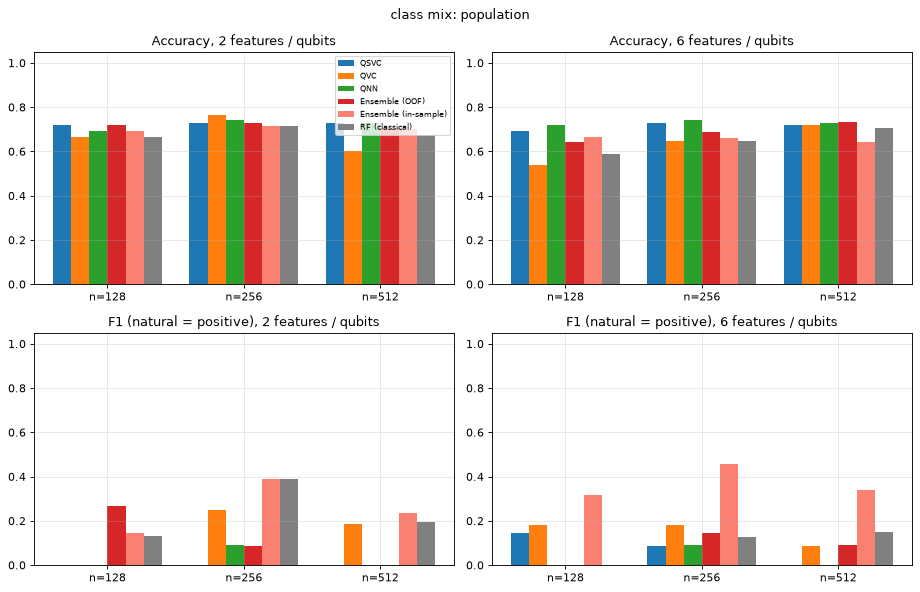

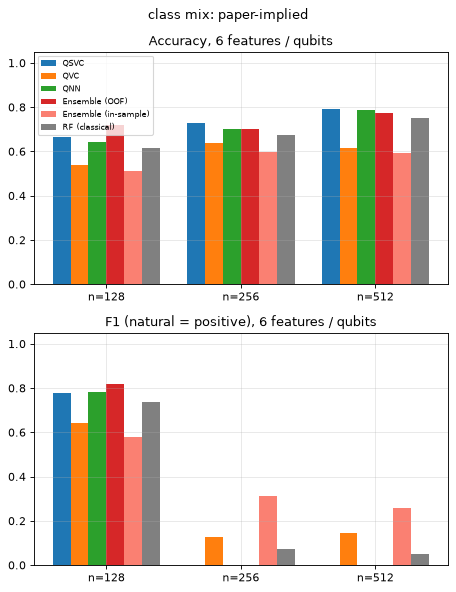

In [14]:
# Re-drawing the style of the paper's Fig. 5: accuracy and F1 per classifier, sample size and feature count
cols = {"QSVC": "tab:blue", "QVC": "tab:orange", "QNN": "tab:green", "Ensemble (OOF)": "tab:red", "Ensemble (in-sample)": "salmon", "RF (classical)": "gray"}
for mix_, ks in MIXES:
    fig, ax = plt.subplots(2, len(ks), figsize=(5.8 * len(ks), 7.5), squeeze=False)
    for j, k in enumerate(ks):
        for i, (met, lab) in enumerate([("acc", "Accuracy"), ("f1", "F1 (natural = positive)")]):
            mods = list(cols); w = 0.8 / len(mods)
            for q, m in enumerate(mods):
                v = [mean.loc[(mix_, m, n, k), met] for n in N_LIST]
                ax[i, j].bar(np.arange(len(N_LIST)) + q * w, v, w, color=cols[m], label=m)
            ax[i, j].set_xticks(np.arange(len(N_LIST)) + 0.4 - w / 2); ax[i, j].set_xticklabels([f"n={n}" for n in N_LIST])
            ax[i, j].set_title(f"{lab}, {k} features / qubits"); ax[i, j].set_ylim(0, 1.05)
    ax[0, 0].legend(fontsize=7)
    plt.suptitle(f"class mix: {mix_}"); plt.tight_layout(); plt.show()

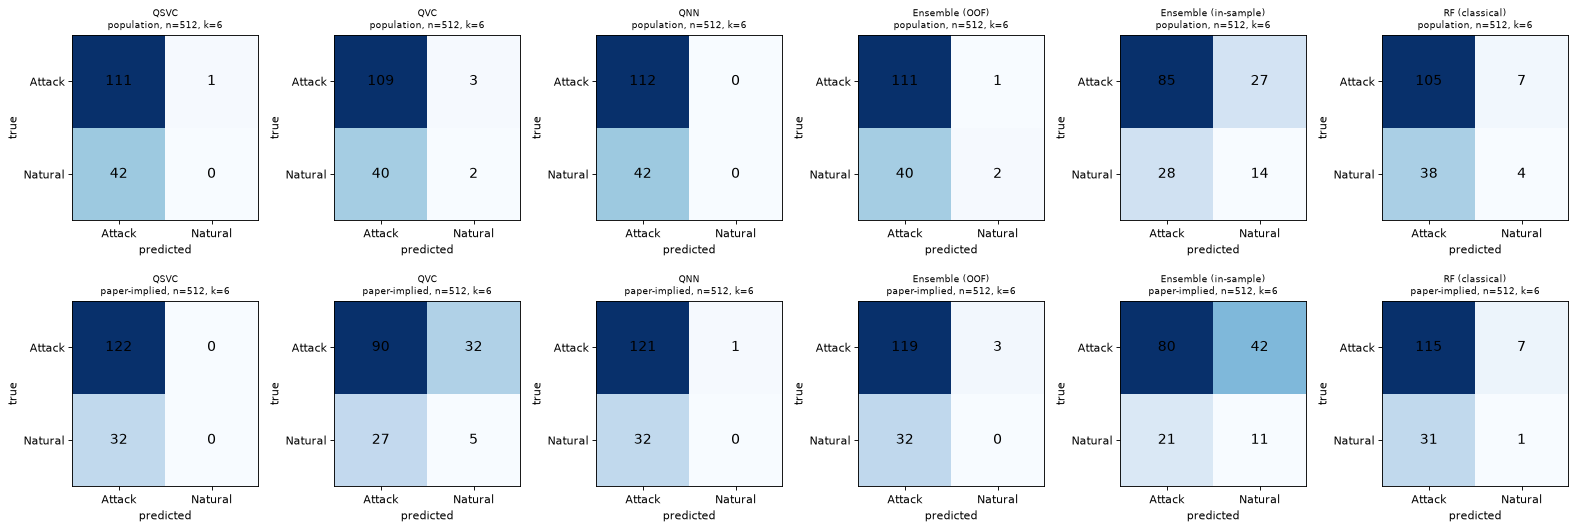

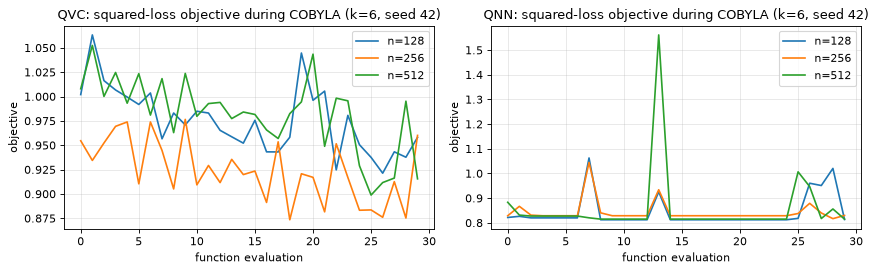

In [15]:
# Confusion matrices (attack = 0, natural = 1) for the largest configuration, first seed, both class mixes
n_c, s_c = max(N_LIST), SEEDS[0]
mods = MODELS_MAIN + ["RF (classical)"]
fig, ax = plt.subplots(len(MIXES), len(mods), figsize=(3.3 * len(mods), 3.4 * len(MIXES)), squeeze=False)
for r_i, (mix_, ks) in enumerate(MIXES):
    k_c = max(ks)
    for a_, m in zip(ax[r_i], mods):
        cm = CONF[(s_c, mix_, n_c, k_c, m)]
        a_.imshow(cm, cmap="Blues"); a_.grid(False)
        for (i, j), v in np.ndenumerate(cm):
            a_.text(j, i, int(v), ha="center", va="center", color="black", fontsize=13)
        a_.set_xticks([0, 1]); a_.set_xticklabels(["Attack", "Natural"]); a_.set_yticks([0, 1]); a_.set_yticklabels(["Attack", "Natural"])
        a_.set_xlabel("predicted"); a_.set_ylabel("true"); a_.set_title(f"{m}\n{mix_}, n={n_c}, k={k_c}", fontsize=8)
plt.tight_layout(); plt.show()

# COBYLA objective histories of the final QVC / QNN fits (population mix, largest k)
k_c = max(K_LIST)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a_, nm in zip(ax, ("QVC", "QNN")):
    for n in N_LIST:
        a_.plot(HISTS[(s_c, "population", n, k_c, nm)], label=f"n={n}")
    a_.set_title(f"{nm}: squared-loss objective during COBYLA (k={k_c}, seed {s_c})"); a_.set_xlabel("function evaluation"); a_.set_ylabel("objective"); a_.legend()
plt.tight_layout(); plt.show()

## 7. Side-by-side comparison with the paper's Table 1

The paper's numbers (copied from Table 1) are compared with the mean of our runs, once for each class mix. Verdict per row: **reproduced** if accuracy and F1 are both within 0.02 (2 points) of the paper;
otherwise **not reached** (our F1 is lower by more than 0.02), **exceeded** (higher by more than 0.02), or decided by accuracy when the F1 values agree.
Then one verdict per claim of the paper.

In [16]:
PAPER_T1 = """
QSVM 128 2 0.717949 0.807018 0.718750 0.920000
VQC 128 2 0.666667 0.779661 0.676471 0.920000
QNN 128 2 0.666667 0.771930 0.687500 0.880000
Ensemble 128 2 0.820513 0.857143 0.875000 0.840000
QSVM 128 4 0.692308 0.800000 0.685714 0.960000
VQC 128 4 0.589744 0.714286 0.645161 0.800000
QNN 128 4 0.666667 0.771930 0.687500 0.880000
Ensemble 128 4 0.794872 0.840000 0.840000 0.840000
QSVM 128 6 0.794872 0.857143 0.774194 0.960000
VQC 128 6 0.743590 0.827586 0.727273 0.960000
QNN 128 6 0.666667 0.763636 0.700000 0.840000
Ensemble 128 6 0.871795 0.897959 0.916667 0.880000
QSVM 256 2 0.662338 0.000000 0.000000 0.000000
VQC 256 2 0.688312 0.076923 0.200000 0.047619
QNN 256 2 0.675325 0.000000 0.000000 0.000000
Ensemble 256 2 0.714286 0.153846 0.400000 0.095238
QSVM 256 4 0.688312 0.250000 0.363636 0.190476
VQC 256 4 0.688312 0.000000 0.000000 0.000000
QNN 256 4 0.675325 0.137931 0.250000 0.095238
Ensemble 256 4 0.792208 0.619048 0.619048 0.619048
QSVM 256 6 0.727273 0.222222 0.500000 0.142857
VQC 256 6 0.714286 0.000000 0.000000 0.000000
QNN 256 6 0.727273 0.222222 0.500000 0.142857
Ensemble 256 6 0.909091 0.810811 0.937500 0.714286
QSVM 512 2 0.792208 0.000000 0.000000 0.000000
VQC 512 2 0.792208 0.000000 0.000000 0.000000
QNN 512 2 0.785714 0.000000 0.000000 0.000000
Ensemble 512 2 0.785714 0.352941 0.473684 0.281250
QSVM 512 4 0.779221 0.000000 0.000000 0.000000
VQC 512 4 0.792208 0.000000 0.000000 0.000000
QNN 512 4 0.792208 0.000000 0.000000 0.000000
Ensemble 512 4 0.837662 0.390244 0.888889 0.250000
QSVM 512 6 0.792208 0.000000 0.000000 0.000000
VQC 512 6 0.792208 0.000000 0.000000 0.000000
QNN 512 6 0.792208 0.000000 0.000000 0.000000
Ensemble 512 6 0.844156 0.428571 0.900000 0.281250
"""
P = pd.DataFrame([l.split() for l in PAPER_T1.strip().splitlines()], columns=["pm", "n", "k", "acc", "f1", "prec", "rec"])
P[["n", "k"]] = P[["n", "k"]].astype(int); P[["acc", "f1", "prec", "rec"]] = P[["acc", "f1", "prec", "rec"]].astype(float)
P["model"] = P["pm"].map({"QSVM": "QSVC", "VQC": "QVC", "QNN": "QNN", "Ensemble": "Ensemble (OOF)"})
rows = []
for mix_, ks in MIXES:
    for _, r in P.iterrows():
        if r["k"] not in ks: continue
        for mv in [r["model"]] + (["Ensemble (in-sample)"] if r["pm"] == "Ensemble" else []):
            m = mean.loc[(mix_, mv, r["n"], r["k"])]
            da, df_ = m["acc"] - r["acc"], m["f1"] - r["f1"]
            if abs(da) <= 0.02 and abs(df_) <= 0.02: v = "reproduced"
            elif df_ < -0.02: v = "not reached"
            elif df_ > 0.02: v = "exceeded"
            else: v = "not reached" if da < 0 else "exceeded"
            rows.append(dict(mix=mix_, model=mv, n=r["n"], k=r["k"], paper_acc=r["acc"], nb_acc=m["acc"], d_acc=da, paper_f1=r["f1"], nb_f1=m["f1"], d_f1=df_, verdict=v))
CMP = pd.DataFrame(rows)
display(CMP.round(3))
print("\nVerdicts per class mix and model (rows of Table 1 that were run):")
display(pd.crosstab([CMP["mix"], CMP["model"]], CMP["verdict"]))

,mix,model,n,k,paper_acc,nb_acc,d_acc,paper_f1,nb_f1,d_f1,verdict
0,population,QSVC,128,2,0.718,0.718,-0.000,0.807,0.000,-0.807,not reached
1,population,QVC,128,2,0.667,0.667,-0.000,0.780,0.000,-0.780,not reached
2,population,QNN,128,2,0.667,0.692,0.026,0.772,0.000,-0.772,not reached
3,population,Ensemble (OOF),128,2,0.821,0.718,-0.103,0.857,0.267,-0.590,not reached
4,population,Ensemble (in-sample),128,2,0.821,0.692,-0.128,0.857,0.143,-0.714,not reached
5,population,QSVC,128,6,0.795,0.692,-0.103,0.857,0.143,-0.714,not reached
6,population,QVC,128,6,0.744,0.538,-0.205,0.828,0.182,-0.646,not reached
7,population,QNN,128,6,0.667,0.718,0.051,0.764,0.000,-0.764,not reached
8,population,Ensemble (OOF),128,6,0.872,0.641,-0.231,0.898,0.000,-0.898,not reached
9,population,Ensemble (in-sample),128,6,0.872,0.667,-0.205,0.898,0.316,-0.582,not reached



Verdicts per class mix and model (rows of Table 1 that were run):


verdict                             exceeded  not reached  reproduced
mix           model                                                  
paper-implied Ensemble (OOF)               0            3           0
              Ensemble (in-sample)         0            3           0
              QNN                          0            2           1
              QSVC                         0            2           1
              QVC                          2            1           0
population    Ensemble (OOF)               0            6           0
              Ensemble (in-sample)         1            5           0
              QNN                          1            5           0
              QSVC                         1            5           0
              QVC                          4            2           0

In [17]:
ind = ["QSVC", "QVC", "QNN"]
verd = []
for mix_, ks in MIXES:
    pick = lambda model, n, k, col: mean.loc[(mix_, model, n, k), col]
    cfgs = [(n, k) for k in ks for n in N_LIST]; N = len(cfgs)
    # C1: ensemble better than every individual quantum classifier in accuracy AND F1 (strictly)
    c1 = {mv: sum(all(pick(mv, n, k, "acc") > pick(m, n, k, "acc") and pick(mv, n, k, "f1") > pick(m, n, k, "f1") for m in ind) for n, k in cfgs)
          for mv in ("Ensemble (OOF)", "Ensemble (in-sample)")}
    # C2: individual classifiers at F1 = 0 for n = 512
    cell512 = [(m, k) for m in ind for k in ks]
    c2_zero = sum(pick(m, 512, k, "f1") < 0.005 for m, k in cell512)
    c2_ens = {k: round(float(pick("Ensemble (OOF)", 512, k, "f1")), 3) for k in ks}
    # C5: ensemble versus the plain Random Forest on the same inputs (F1 better by more than 0.02)
    c5 = {mv: sum(pick(mv, n, k, "f1") > pick("RF (classical)", n, k, "f1") + 0.02 for n, k in cfgs) for mv in c1}
    sub = CMP[(CMP["mix"] == mix_)]
    nrep, nrow = int((sub["verdict"] == "reproduced").sum()), len(sub)
    verd.append((mix_, "C1 ensemble beats all three quantum models in accuracy and F1 (paper: in all 9 configurations)",
                 f"OOF ensemble in {c1['Ensemble (OOF)']}/{N}; in-sample ensemble in {c1['Ensemble (in-sample)']}/{N}",
                 "reproduced" if max(c1.values()) == N else "not reached"))
    verd.append((mix_, "C2 individual quantum classifiers have F1 = 0 at n = 512 (paper: 9/9 cells)",
                 f"{c2_zero}/{len(cell512)} cells have F1 = 0; OOF-ensemble F1 at n=512 by k: {c2_ens} (paper: k=2 0.353, k=4 0.390, k=6 0.429)",
                 "reproduced" if c2_zero == len(cell512) else "not reached"))
    if (128, 6) in cfgs:
        a_, f_ = pick("Ensemble (OOF)", 128, 6, "acc"), pick("Ensemble (OOF)", 128, 6, "f1")
        verd.append((mix_, "C3 headline: ensemble n=128, k=6, accuracy 0.872 and F1 0.898",
                     f"OOF ensemble accuracy {a_:.3f}, F1 {f_:.3f}",
                     "reproduced" if abs(a_ - 0.8718) <= 0.02 and abs(f_ - 0.8980) <= 0.02 else ("exceeded" if f_ > 0.918 else "not reached")))
    verd.append((mix_, f"C4 every Table-1 row that was run ({nrow} model-rows incl. both ensemble variants)",
                 f"{nrep} reproduced, {int((sub['verdict'] == 'not reached').sum())} not reached, {int((sub['verdict'] == 'exceeded').sum())} exceeded",
                 "reproduced" if nrep == nrow else ("partly reproduced" if nrep >= nrow / 2 else "not reached")))
    verd.append((mix_, "C5 (our check) ensemble better than a plain Random Forest on the same inputs by more than 0.02 F1",
                 f"OOF ensemble better in {c5['Ensemble (OOF)']}/{N} configurations; in-sample ensemble in {c5['Ensemble (in-sample)']}/{N}",
                 "supports a quantum contribution" if c5["Ensemble (OOF)"] >= N * 2 / 3 else "no evidence that the quantum models add value beyond the RF"))
V = pd.DataFrame(verd, columns=["class mix", "claim", "notebook result", "verdict"])
pd.set_option("display.max_colwidth", 220)
display(V)
print(f"Total notebook time: {(time.time() - T0) / 60:.1f} min  (FAST_MODE={FAST_MODE})")

,class mix,claim,notebook result,verdict
0,population,C1 ensemble beats all three quantum models in accuracy and F1 (paper: in all 9 configurations),OOF ensemble in 1/6; in-sample ensemble in 0/6,not reached
1,population,C2 individual quantum classifiers have F1 = 0 at n = 512 (paper: 9/9 cells),"4/6 cells have F1 = 0; OOF-ensemble F1 at n=512 by k: {2: 0.0, 6: 0.089} (paper: k=2 0.353, k=4 0.390, k=6 0.429)",not reached
2,population,"C3 headline: ensemble n=128, k=6, accuracy 0.872 and F1 0.898","OOF ensemble accuracy 0.641, F1 0.000",not reached
3,population,C4 every Table-1 row that was run (30 model-rows incl. both ensemble variants),"0 reproduced, 23 not reached, 7 exceeded",not reached
4,population,C5 (our check) ensemble better than a plain Random Forest on the same inputs by more than 0.02 F1,OOF ensemble better in 1/6 configurations; in-sample ensemble in 4/6,no evidence that the quantum models add value beyond the RF
5,paper-implied,C1 ensemble beats all three quantum models in accuracy and F1 (paper: in all 9 configurations),OOF ensemble in 1/3; in-sample ensemble in 0/3,not reached
6,paper-implied,C2 individual quantum classifiers have F1 = 0 at n = 512 (paper: 9/9 cells),"2/3 cells have F1 = 0; OOF-ensemble F1 at n=512 by k: {6: 0.0} (paper: k=2 0.353, k=4 0.390, k=6 0.429)",not reached
7,paper-implied,"C3 headline: ensemble n=128, k=6, accuracy 0.872 and F1 0.898","OOF ensemble accuracy 0.718, F1 0.820",not reached
8,paper-implied,C4 every Table-1 row that was run (15 model-rows incl. both ensemble variants),"2 reproduced, 11 not reached, 2 exceeded",not reached
9,paper-implied,C5 (our check) ensemble better than a plain Random Forest on the same inputs by more than 0.02 F1,OOF ensemble better in 1/3 configurations; in-sample ensemble in 2/3,no evidence that the quantum models add value beyond the RF


Total notebook time: 11.1 min  (FAST_MODE=True)


## 8. Reading the paper critically

The numbers quoted in this section are from the executed `FAST_MODE = True` run saved in this notebook (one seed; 30 COBYLA iterations; `K_LIST = [2, 6]`, `paper-implied` mix only at 6 qubits). Re-run with `FAST_MODE = False` for the larger budgets.

1. **Table 1 mixes up model quality and class prevalence.** Table 1's recalls and accuracies imply test sets with 64 % positives at n = 128, 27 % at n = 256 and 21 % at n = 512. A uniform random sample of the real dataset has about 29 % natural rows, so the n = 128 test set of the paper is far from the population. With 64 % positives, a classifier that says "positive" for every row already has accuracy 0.64 and F1 0.78. In our `paper-implied` run an RBF-SVC reaches exactly that (accuracy 0.641, F1 0.781), and QSVC (0.780) and QNN (0.781) are indistinguishable from it. The paper's n = 128 base-model F1 values of 0.76 to 0.86 therefore say little about quantum learning. The paper's "decline" of the base models with more data is the same artefact seen from the other side: with 21 % positives the trivial all-negative answer has accuracy 0.79 and F1 = 0, which is what almost all models here (quantum or classical) return at n = 512.
2. **The ensemble's edge is not demonstrated.** In our runs the OOF ensemble reaches F1 0.82 (accuracy 0.718, precision 0.694, recall 1.0) at n = 128 / 6 qubits with the paper-implied mix, above the trivial 0.78 but below the paper's 0.898; at n = 256 and 512 it falls back to F1 = 0. With the real class balance it is not better than the plain Random Forest on the same angles in most configurations (check section 7, claim C5). The paper has no classical baseline, so it cannot say whether the three quantum models contribute anything: the meta-learner is a Random Forest that also receives the raw features (Eq. 5), so a Random Forest alone is the natural control.
3. **The stacking protocol is unspecified, and it matters.** If the Random Forest is trained on the posteriors that the base models give for their own training rows (the naive pipeline), it learns to trust over-confident outputs. Our *Ensemble (in-sample)* variant raises the n = 512 F1 to 0.23 to 0.34, whereas the leak-free *Ensemble (OOF)* stays between 0 and 0.09; the paper reports 0.35 to 0.43 there. That is consistent with, but does not prove, in-sample stacking in the paper. The paper does not say how the training posteriors were produced.
4. **Tiny test sets, one split, no error bars.** A single test row is worth 2.6 accuracy points at n = 128 (39 rows) and F1 moves by several points when one of 11 to 25 positive rows changes class. Table 1 compares configurations differing by a few points, so most of the "consistent outperformance" in Section 5.4 is within sampling noise. Averaging over seeds (`SEEDS`) is the minimum needed to say anything.
5. **Positive class and metrics are not defined.** The text calls natural rows the minority class but never states which class is positive in precision, recall and F1. The collapse to F1 = 0 only makes sense for the minority; with attack as positive (column *F1 (attack)*) the n = 256 and n = 512 predictions of every model would score an attack-positive F1 of about 0.7 to 0.9 (see the *F1 (attack)* column), and the 'scalability problem' of the quantum classifiers would disappear.
6. **Inconsistent or missing details.** The abstract says 78,345 samples, Section 4.1 says 78,377 (the real figure) and "129 features" (128 measurements plus the label). The text announces a reduction to two PCA components, Table 1 uses 2, 4 and 6. Circuits, feature maps, ansatz depth, optimiser, iteration budget, shots, SVM parameters, sampling procedure and random seeds are not given (Figures 1 to 3 are pictures only), so the experiment cannot be repeated exactly. "Real-time" is a label for a recorded testbed dataset, not a streaming evaluation, and "qubit efficiency" is asserted without comparing 2 to 6 qubits against any classical model of the same size.
7. **Limits of this reproduction.** The class mix used in the `paper-implied` runs and the choice of Natural as the positive class are inferred from Table 1, not stated. The architectures are our assumptions. In `FAST_MODE` the COBYLA budget (30 evaluations for 24 or more parameters) barely trains the QVC and QNN; the full budgets (100 iterations, 3 seeds, 3 OOF folds, k = 2, 4, 6 and both mixes) need several hours on a CPU. The dataset is a recorded time series, and a row-level split can leak between neighbouring rows; at n <= 512 out of 78,368 rows this is unlikely to matter, but a file-level hold-out would be the stricter test.

## 9. Exercises

1. **Positive class.** Recompute Table 1 with *attack* as the positive class (use the `f1_attack` column of `RES`). Which of the paper's 'collapses to F1 = 0' disappear, and what does that say about reading F1 on imbalanced data?
2. **Seeds and test size.** Increase `SEEDS` to 10 and plot the spread of the ensemble's F1 for n = 128, k = 6. How often does a single run reach the paper's 0.898 and how often does it fall below the best individual model?
3. **Leakage.** Compare *Ensemble (OOF)* and *Ensemble (in-sample)* for every configuration. Explain, using the confusion matrices, why the meta-learner trusts the base posteriors more than it should in the in-sample version.
4. **Do the qubits matter?** Replace the three quantum base models by their classical counterparts (SVC with an RBF kernel, a small MLP, logistic regression) inside the same stacking code. Does the ensemble change?
5. **Bandwidth and depth.** Change `reps` of the ZZ feature map (1, 2, 3), the `BW_GRID` and the `MAXITER` budget. Which knob helps the QSVC / QVC most at 6 qubits, and does any of them close the gap to a Random Forest on the same six angles?